## 1) Importing All Libraries

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

## 2) Exploring all the data

In [25]:
df=pd.read_csv("StudentPerformanceFactors.csv")
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [26]:
print("Rows,Columns:",df.shape)

Rows,Columns: (6607, 20)


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [28]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [29]:
print(df.isnull().sum())

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


## 3) Cleaning the data
In this we will select empty columns and fill it with mode for text columns and with median for number columns

In [30]:
text_columns=df.select_dtypes(include="object").columns
number_columns=df.select_dtypes(exclude="object").columns
for col in text_columns:
    df[col]=df[col].fillna(df[col].mode()[0])
for col in number_columns:
    df[col]=df[col].fillna(df[col].median())
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


C:\Users\adity\AppData\Local\Temp\ipykernel_3228\1283424852.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns=df.select_dtypes(include="object").columns


## 4) Ploting different graphs
In this through graphs we will understand relation between different factors

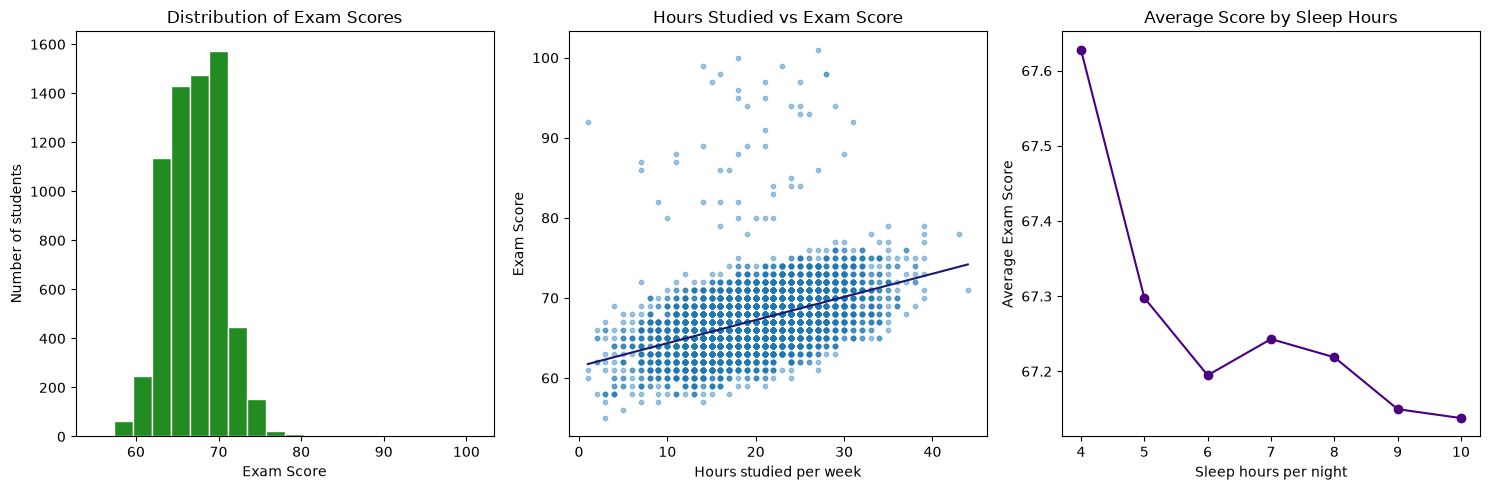

In [31]:
fig,axes=plt.subplots(1,3,figsize=(15,5))

axes[0].hist(df["Exam_Score"],bins=20,color="forestgreen",edgecolor="white")
axes[0].set_title("Distribution of Exam Scores")
axes[0].set_xlabel("Exam Score")
axes[0].set_ylabel("Number of students")

axes[1].scatter(df["Hours_Studied"],df["Exam_Score"],alpha=0.4,s=10)
slope,intercept=np.polyfit(df["Hours_Studied"],df["Exam_Score"],1)
x_line=np.sort(df["Hours_Studied"].unique())
axes[1].plot(x_line,slope*x_line+intercept,color="midnightblue")
axes[1].set_title("Hours Studied vs Exam Score")
axes[1].set_xlabel("Hours studied per week")
axes[1].set_ylabel("Exam Score")

avg_by_sleep=df.groupby("Sleep_Hours")["Exam_Score"].mean()
axes[2].plot(avg_by_sleep.index,avg_by_sleep.values,marker="o",color="indigo")
axes[2].set_title("Average Score by Sleep Hours")
axes[2].set_xlabel("Sleep hours per night")
axes[2].set_ylabel("Average Exam Score")

plt.tight_layout()
plt.show()

## 5) Changing alphabetic/string values to numeric values

In [32]:
df = pd.get_dummies(df, columns=list(text_columns), drop_first=True)
df.head()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,Parental_Involvement_Low,Parental_Involvement_Medium,Access_to_Resources_Low,...,Teacher_Quality_Medium,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Moderate,Distance_from_Home_Near,Gender_Male
0,23,84,7,73,0,3,67,True,False,False,...,True,True,False,True,False,True,False,False,True,True
1,19,64,8,59,2,4,61,True,False,False,...,True,True,False,False,False,False,False,True,False,False
2,24,98,7,91,2,4,74,False,True,False,...,True,True,True,False,False,False,True,False,True,True
3,29,89,8,98,1,4,71,True,False,False,...,True,True,False,False,False,True,False,True,False,True
4,19,92,6,65,3,4,70,False,True,False,...,False,True,True,False,False,False,False,False,True,False


## 6) Separating features (X) and target (y), then spliting the data into training and testing

In [33]:
x=df.drop(columns=["Exam_Score"])
y=df["Exam_Score"]
x_train,x_val,y_train,y_val=train_test_split(
    x,y,test_size=0.5,random_state=20)
print("Training students:",x_train.shape[0])
print("Validation students:",x_val.shape[0])

Training students: 3303
Validation students: 3304


## 7) Training a model and measuring it's MAE
First we will train a linear regression model and measure it's MAE

In [34]:
model=LinearRegression()
model.fit(x_train,y_train)
predictions=model.predict(x_val)
mae=mean_absolute_error(y_val,predictions)
print("Linear Regression validation MAE:",mae)

Linear Regression validation MAE: 0.46828917637197476


## 8) Comparing several models on the same validation split
In this we have created a baseline predictions and baseline mae which are benchmark,i.e., any useful model should score better than this

In [35]:
baseline_predictions=np.full(len(y_val),y_train.mean())
baseline_mae=mean_absolute_error(y_val,baseline_predictions)

models={"Linear Regression": LinearRegression(),
    "Decision Tree":DecisionTreeRegressor(max_depth=5,random_state=20),
    "Random Forest": RandomForestRegressor(n_estimators=100,random_state=20)}

results={"Baseline(always the mean)":baseline_mae}
for name,m in models.items():
    m.fit(x_train,y_train)
    predictions=m.predict(x_val)
    results[name]=mean_absolute_error(y_val,predictions)
results_table=(pd.Series(results,name="Validation MAE").sort_values())
print(results_table)

Linear Regression            0.468289
Random Forest                1.344304
Decision Tree                1.709240
Baseline(always the mean)    2.804626
Name: Validation MAE, dtype: float64


## 9) Finding the best model and its validation MAE

In [36]:
best_model=results_table.drop("Baseline(always the mean)").idxmin()
best_mae = results_table[best_name]
print("Best model:",best_model)
print("Validation MAE:",best_mae)
print("On average, its predictions are about",best_mae,"marks away from the real exam score.")

Best model: Linear Regression
Validation MAE: 0.46828917637197476
On average, its predictions are about 0.46828917637197476 marks away from the real exam score.


In [37]:
forest=models["Random Forest"]
importance=pd.Series(forest.feature_importances_,index=x.columns)
print(importance.sort_values(ascending=False).head(8))

Attendance                  0.379112
Hours_Studied               0.236730
Previous_Scores             0.097592
Tutoring_Sessions           0.038463
Sleep_Hours                 0.036784
Physical_Activity           0.029844
Parental_Involvement_Low    0.019635
Access_to_Resources_Low     0.013328
dtype: float64
